In [ ]:
import os
import uuid
import torch
import numpy as np
from PIL import Image
from ultralytics import YOLO
import open_clip
from tqdm import tqdm
from torchvision.ops import nms
from transformers import CLIPModel, CLIPProcessor
import cv2


c:\Users\liuja\Desktop\OceanX\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [92]:
# ------------------
# Config
# ------------------
YOLO_MODEL_A = "models/benthic_object_detector.pt"
YOLO_MODEL_B = "models/midwater_object_detector.pt"
IMAGE_PATH = "fish.jpg"
ROI_DIR = "rois"
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
CLIP_CHECKPOINT = "open_clip_pytorch_model_bioclip2.bin"
CONF_THRESH = 0.01   # as low as YOLO allows reliably
IOU_THRESH = 0.9     # very permissive NMS inside YOLO
NMS_IOU_THRESH = 0.5
MIN_BOX_AREA = 32 * 32
OUTPUT_DIR = "embeddings"
os.makedirs(ROI_DIR, exist_ok=True)


In [13]:
# ------------------
# Load YOLO models
# ------------------
yolo_a = YOLO(YOLO_MODEL_A)
yolo_b = YOLO(YOLO_MODEL_B)



In [19]:
# ------------------
# Load CLIP
# ------------------
clip_model, _, clip_preprocess = open_clip.create_model_and_transforms('hf-hub:imageomics/bioclip-2')
tokenizer = open_clip.get_tokenizer('hf-hub:imageomics/bioclip-2')
clip_model = clip_model.to(DEVICE).eval()


c:\Users\liuja\Desktop\OceanX\.venv\Lib\site-packages\huggingface_hub\file_download.py:143: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\liuja\.cache\huggingface\hub\models--imageomics--bioclip-2. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


In [93]:
# ------------------
# Load image
# ------------------
image = Image.open(IMAGE_PATH).convert("RGB")

In [94]:
# ------------------
# Run both detectors
# ------------------
res_a = yolo_a(
    image,
    conf=CONF_THRESH,
    iou=IOU_THRESH,
    verbose=False
)[0]

res_b = yolo_b(
    image,
    conf=CONF_THRESH,
    iou=IOU_THRESH,
    verbose=False
)[0]

boxes_a = res_a.boxes.xyxy.cpu()
scores_a = res_a.boxes.conf.cpu()

boxes_b = res_b.boxes.xyxy.cpu()
scores_b = res_b.boxes.conf.cpu()

In [95]:
# ------------------
# Concatenate predictions
# ------------------
boxes = torch.cat([boxes_a, boxes_b], dim=0)
scores = torch.cat([scores_a, scores_b], dim=0)

print(f"Raw detections: {len(boxes)}")


Raw detections: 25


In [96]:
# ------------------
# Cross-model NMS
# ------------------
keep = nms(boxes, scores, NMS_IOU_THRESH)

boxes = boxes[keep]
scores = scores[keep]

print(f"After NMS: {len(boxes)}")


After NMS: 8


In [97]:
# ------------------
# Crop ROIs
# ------------------
roi_images = []
roi_paths = []

for i, box in enumerate(boxes):
    x1, y1, x2, y2 = map(int, box)
    crop = image.crop((x1, y1, x2, y2))

    roi_id = str(uuid.uuid4())
    path = os.path.join(ROI_DIR, f"{roi_id}.jpg")
    crop.save(path, quality=95)

    roi_images.append(crop)
    roi_paths.append(path)


In [98]:
#OPTIONAL
roi_images = []
roi_paths = []

for f in os.listdir(ROI_DIR):
    if f.lower().endswith((".jpg", ".jpeg", ".png")):
        path = os.path.join(ROI_DIR, f)
        img = Image.open(path).convert("RGB")
        roi_images.append(img)
        roi_paths.append(path)

print(f"Loaded {len(roi_images)} ROI images from '{ROI_DIR}'")

Loaded 97 ROI images from 'rois'


In [99]:
# ------------------
# Embed ROIs
# ------------------
def embed_images(images):
    with torch.no_grad():
        batch = torch.stack([
            clip_preprocess(img) for img in images
        ]).to(DEVICE)

        feats = clip_model.encode_image(batch)
        feats = feats / feats.norm(dim=-1, keepdim=True)

    return feats.cpu().numpy()

if roi_images:
    embeddings = embed_images(roi_images)
else:
    embeddings = np.empty((0, 512))


In [118]:
# ------------------
# Output
# ------------------
for i in range(len(embeddings)):
    print(f"\nROI {i}")
    print(f" Path: {roi_paths[i]}")
    print(f" Embedding shape: {embeddings[i].shape}")
    print(f" Embeddings: {embeddings[i]}")

print("\nDone.")
print(len(embeddings))


ROI 0
 Path: rois\036d6633-ac34-47ee-bd84-edd93ce14e1b.jpg
 Embedding shape: (768,)
 Embeddings: [    0.10085    0.049988    0.011994   -0.072424   -0.013093   -0.028713  0.00054812     0.05636   -0.024089   -0.033095    0.032625  -0.0047276   -0.059725    -0.01571    0.056453    -0.02727   -0.040417   0.0067109    0.021269    0.072704   -0.015518    0.012975  -0.0036176   -0.022153  -0.0031387   0.0050679
    0.045782   -0.013847   -0.032816    0.042623   0.0093598  -0.0033282     0.03951   0.0037206   -0.013841   0.0083985    0.056361   -0.019748    0.042258   -0.019127   -0.019451     0.06434   -0.014471    0.012744     -0.0883   -0.062197    0.037882   0.0044998    0.045579   -0.042235     0.01862   -0.042612
    0.006897  -0.0083149  -0.0020572   0.0049502    0.048976   -0.036874     0.00955    0.032309   0.0023091   -0.025927   -0.019217    -0.03686    0.017378    0.060753   -0.011507    0.043737  -0.0035513 -0.00078202   0.0071448    -0.01062   -0.020541   -0.029113    -0.15873

In [119]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import hdbscan
import random

In [172]:
# -------------------------
# Config
# -------------------------
NUM_EXAMPLES_PER_CLUSTER = 10
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

In [121]:
# -------------------------
# Optional: reduce dimensionality for clustering
# -------------------------
# HDBSCAN works better with lower-dim data, PCA to 50 dims
pca = PCA(n_components=min(50, embeddings.shape[1]))
embeddings_reduced = pca.fit_transform(embeddings)

In [173]:
from sklearn.cluster import KMeans

NUM_CLUSTERS = 7 # choose how many clusters you want

kmeans = KMeans(n_clusters=NUM_CLUSTERS, random_state=42)
cluster_labels = kmeans.fit_predict(embeddings)  # or embeddings_reduced


In [191]:
# -------------------------
# Cluster with HDBSCAN
# -------------------------
clusterer = hdbscan.HDBSCAN(
    min_cluster_size=2,
    metric='euclidean',
    cluster_selection_epsilon=0.000000,
    max_cluster_size=50,
    cluster_selection_method='leaf'
)

cluster_labels = clusterer.fit_predict(embeddings)
num_clusters = len(set(cluster_labels)) - (1 if -1 in cluster_labels else 0)
print(f"Found {num_clusters} clusters (excluding noise)")

Found 12 clusters (excluding noise)


In [192]:
# -------------------------
# Organize ROI paths by cluster
# -------------------------
clusters = {}
for path, label in zip(roi_paths, cluster_labels):
    if label not in clusters:
        clusters[label] = []
    clusters[label].append(path)
for label in clusters:
    print(label, len(clusters[label]))

-1 49
9 5
1 10
0 7
8 4
3 3
5 4
10 2
11 3
2 3
6 3
4 2
7 2



Cluster 9: 5 ROIs


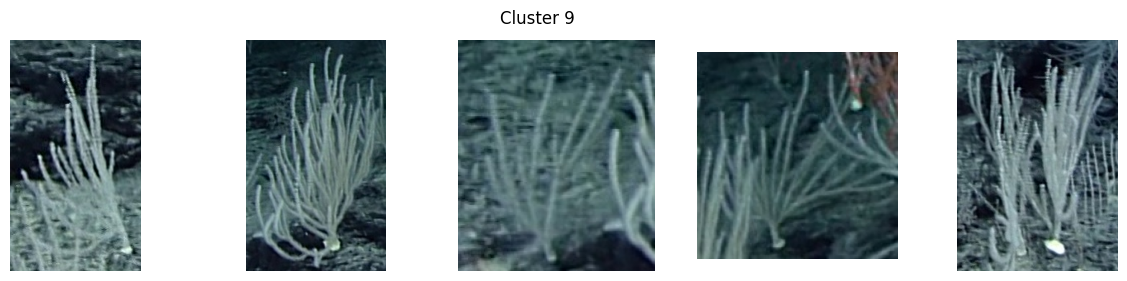


Cluster 1: 10 ROIs


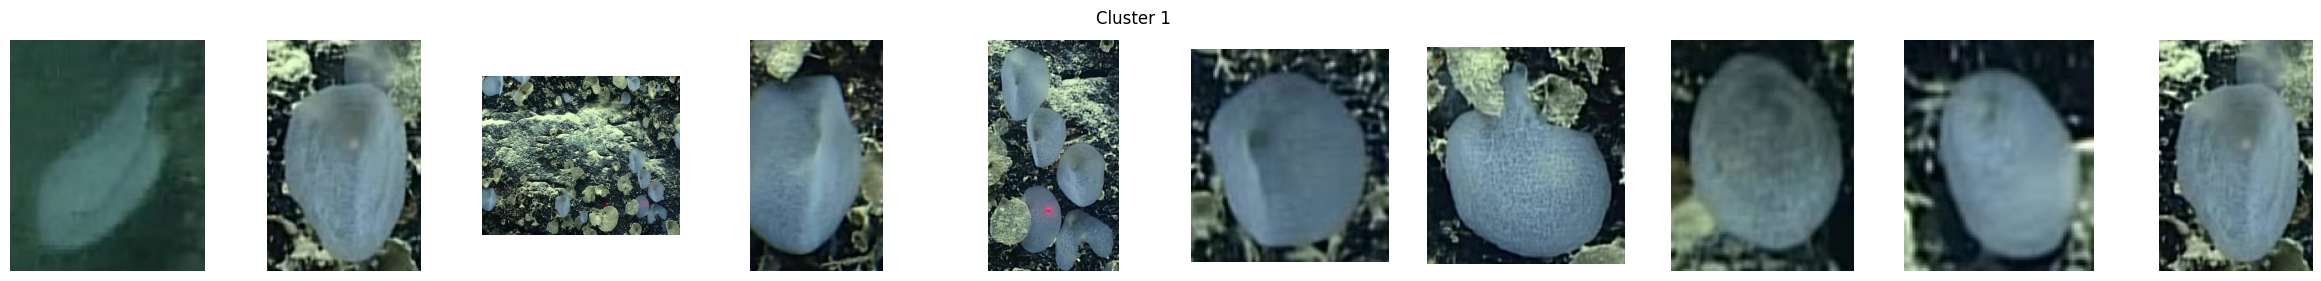


Cluster 0: 7 ROIs


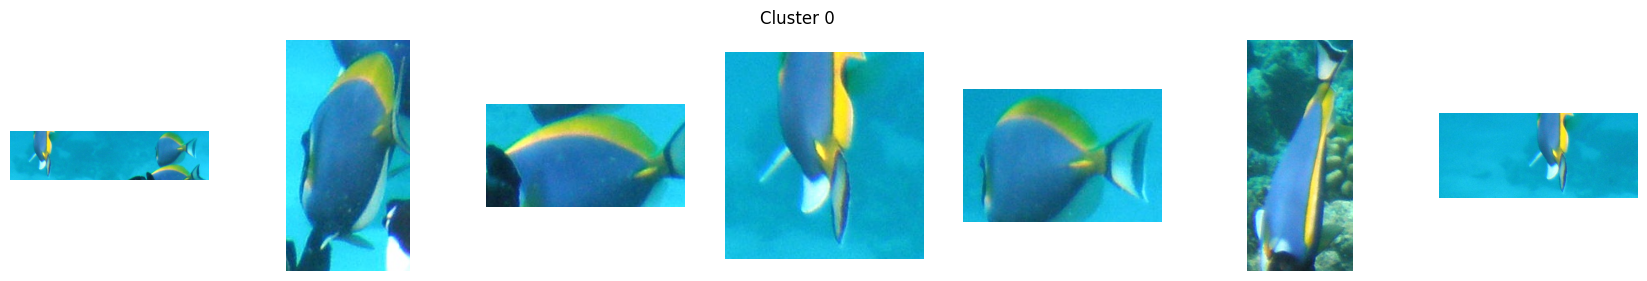


Cluster 8: 4 ROIs


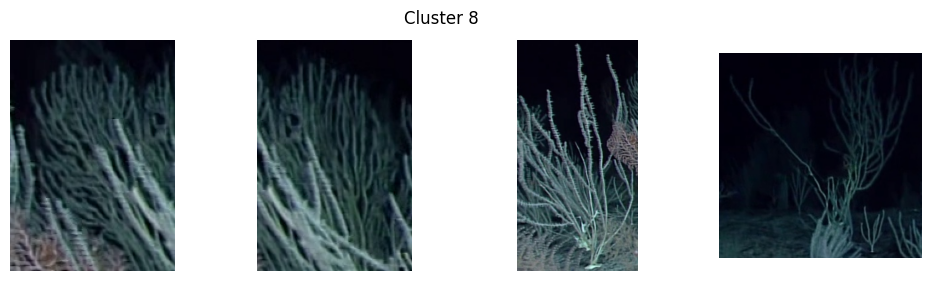


Cluster 3: 3 ROIs


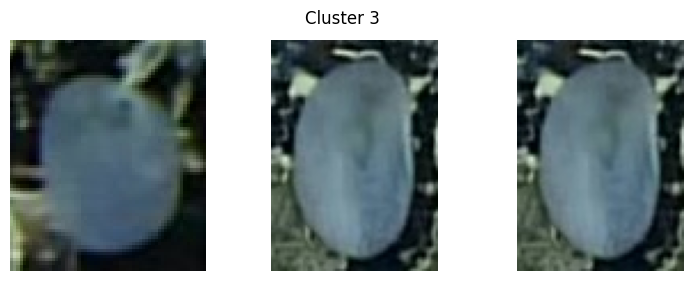


Cluster 5: 4 ROIs


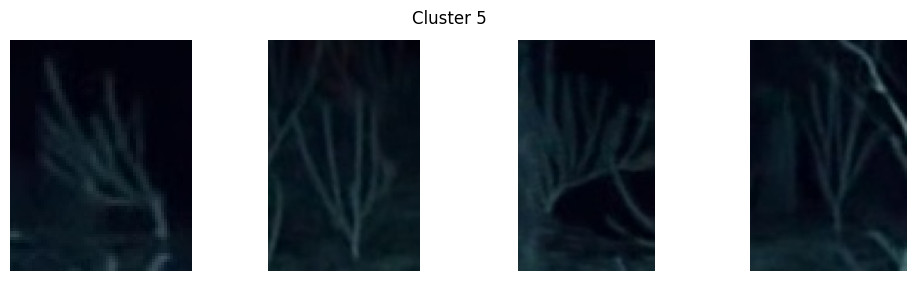


Cluster 10: 2 ROIs


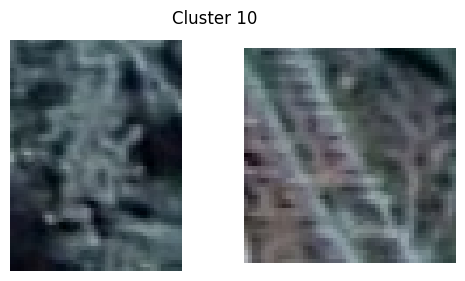


Cluster 11: 3 ROIs


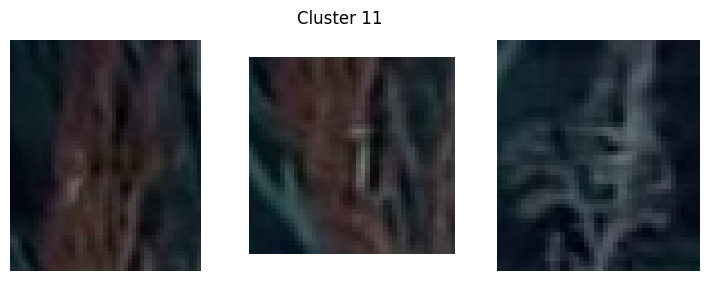


Cluster 2: 3 ROIs


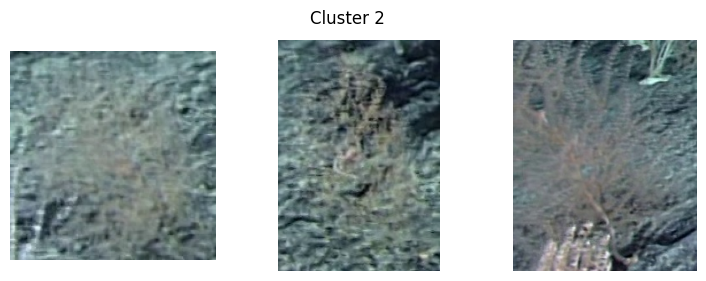


Cluster 6: 3 ROIs


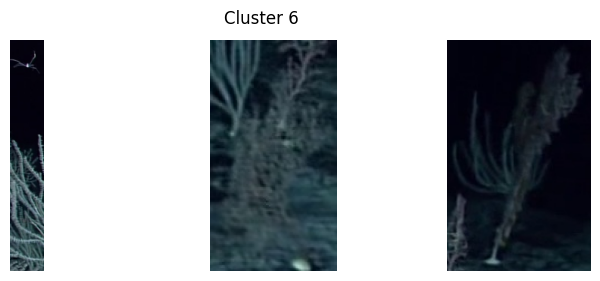


Cluster 4: 2 ROIs


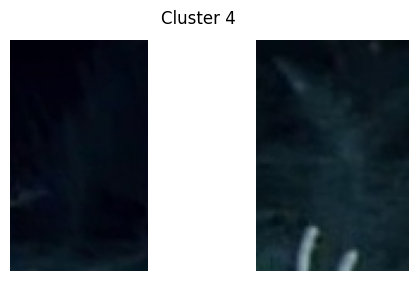


Cluster 7: 2 ROIs


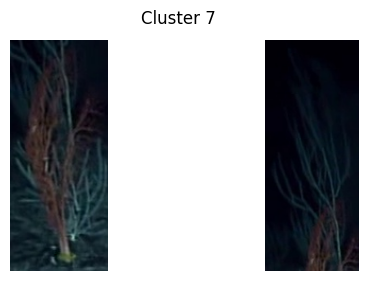

In [187]:
# -------------------------
# Display 5 examples per cluster
# -------------------------
for label, paths in clusters.items():
    if label == -1:
        # skip noise points if desired
        continue

    print(f"\nCluster {label}: {len(paths)} ROIs")

    example_paths = random.sample(paths, min(NUM_EXAMPLES_PER_CLUSTER, len(paths)))

    fig, axes = plt.subplots(1, len(example_paths), figsize=(3*len(example_paths), 3))
    if len(example_paths) == 1:
        axes = [axes]
    for ax, p in zip(axes, example_paths):
        img = Image.open(p)
        ax.imshow(img)
        ax.axis('off')
    plt.suptitle(f"Cluster {label}")
    plt.show()